# Demo ECA&D OGC EDR API for RODEO project
## Abstract
This notebook demonstrates how to explore the ECA&D non-blended collection through the OGC Environmental Data Retrieval (EDR) API used in the RODEO project. It walks through the main discovery and request patterns: inspecting collection metadata, finding stations, requesting station time series, and running polygon queries for larger regions.

Each API request prints the full URL before the response is processed. This makes the notebook useful even if you are not focused on Python: the printed URL shows what the API call looks like and can be copied into a browser or another client.

The notebook is structured as follows:
1. Set up the Python environment and helper functions for readable API requests.
2. Inspect what the ECA&D collection provides, including variables, metadata, and spatial/temporal coverage.
3. Plot all available ECA&D stations to understand the observation network.
4. Query an individual station, using De Bilt as an example, and inspect returned observations.
5. Run polygon queries, using an illustrative Rhine-area polygon, to retrieve observations for a region.
6. Compare the number of stations in the polygon between the non-blended and the blended collection.
7. Inspect the provider lineage of stations, for the non-blended and the blended collection.

Last update: 2026.11.17

J.R. Angevaare (joran.angevaare@knmi.nl)

## Not included in this demonstration
 - area query (https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/docs#/ecad-nonblended/get_collections_ecad_nonblended_area)
 - position query (https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/docs#/ecad-nonblended/get_collections_ecad_nonblended_position)
 - netcdf4 requests (see basic_demo.ipynb)


## Resources
 - For ECA&D see [www.ecad.eu](http://www.ecad.eu/)
 - For the technical (swagger) documation of the API, examples and settings, please see https://api.meteogate.eu/eu-eumetnet-climate-observations

## Setup and helper functions

This first block imports the packages used throughout the notebook. 

In [1]:
import numpy as np
import cartopy
import pandas as pd
import requests
import pprint
import matplotlib.pyplot as plt
import datetime
import time
from shapely import wkt
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import ipywidgets as widgets
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import ipywidgets as widgets
from matplotlib.colors import LogNorm

This block defines the API endpoint and the collection used in all following requests. `base_url` points to the EUMETNET Climate Observations EDR API, `collection` selects the ECA&D non-blended data, and `SCREEN_WIDTH` controls how wide printed example responses are shown.

In [2]:
base_url = "https://api.meteogate.eu/eu-eumetnet-climate-observations/v1"
collection = "ecad-nonblended"
SCREEN_WIDTH = 120

This helper wraps `requests.get`. It prints the full URL that is sent to the API before making the request, reports how long the request took, checks for HTTP errors, and returns the JSON response as a Python dictionary. The printed URL is useful for non-Python users because it shows the endpoint and query parameters directly.

In [3]:
def get_request(url, params=None, **kwargs):
    """Get request, print url of the formatted request"""
    print(
        requests.Request("GET", url, params=params, **kwargs).prepare().url,
    )
    t0 = time.time()
    r = requests.get(url, params=params, **kwargs)
    print(f"API call took {time.time()-t0:.2g} s")
    r.raise_for_status()
    return r.json()

## Collection metadata

Before requesting observations, we first ask the API for metadata about the ECA&D non-blended collection. This tells us what the collection is, where it comes from, and what usage information is attached to it. The first output line of the request cell is the exact API URL.

In [4]:
collection_info = get_request(f"{base_url}/collections/{collection}")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended


API call took 0.43 s


The raw metadata response contains a description field. This block prints that description in a readable form, so the notebook shows the collection summary and attribution information directly.

In [5]:
print("".join(collection_info["description"]))

European Climate Assessment & Dataset (ECA&D)

The non-blended series (this collection) are the series as provided by the participants.

The provided data focuses on European meteorological observations.
For more information on ECA&D and additional datasets, see https://www.ecad.eu.
The Algorithm Theoretical Basis Document can be found here https://www.ecad.eu/documents/atbd.pdf.

To filter locations and data by country, add the optional "country_code" query parameter to the request URL,
for example "country_code=NL,BE" for the Netherlands and Belgium. Use a comma-separated list of uppercase
ISO 3166 alpha-2 country codes. Available codes are listed in the "country_code" custom dimension of the
collection metadata. This parameter is supported but is not listed in the API documentation.

These data can be used for non-commercial research and education provided that the following source is acknowledged:
Klein Tank, A.M.G. and Coauthors, 2002. Daily dataset of 20th-century surface air tem

## Plot all stations in ECA&D

This section retrieves all station locations in the collection and turns the response into a table that is easier to inspect and plot. The goal is to understand where the stations are and how much observational coverage each station contributes. The request cell prints the `/locations` URL before showing the response.

In [6]:
stations = get_request(f"{base_url}/collections/{collection}/locations")
print("-- example response --")
pprint.pprint(stations["features"][0], width=SCREEN_WIDTH)

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/locations


API call took 5.2 s
-- example response --
{'geometry': {'coordinates': [14.8, 56.86667], 'type': 'Point'},
 'id': 'ecad_0000001',
 'properties': {'country_code': 'SE',
                'height_above_mean_sea_level': 166.0,
                'provider': {'Marcus Flarup': {'cc13': [['1961-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'dd4': [['1947-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'pp18': [['1961-01-02T00:00:00', '1995-11-15T00:00:00']],
                                               'rr9': [['1860-01-02T00:00:00', '2019-09-17T00:00:00']],
                                               'sd5': [['1881-10-27T00:00:00', '2019-05-01T00:00:00']],
                                               'tg6': [['1860-01-02T00:00:00', '2006-12-01T00:00:00']],
                                               'tn2': [['1882-01-02T00:00:00', '2006-12-01T00:00:00']],
                                               

This small check counts how many station features were returned by the `/locations` endpoint. It is a quick sanity check that the station discovery request returned the full network.

In [7]:
print(f'In total, we have {len(stations["features"])} stations')

In total, we have 22972 stations


The helper function below estimates the total number of observation days available for a station by reading the time ranges in the station metadata. This value is later used to color the station map by data availability.

The station response is CovJson (GeoJson-like) and nested, which is useful for APIs but not ideal for analysis. This block flattens the important fields into a pandas DataFrame: station id, elevation, station name, longitude, latitude, and an estimated number of observation days.

In [8]:
%%time


def get_days_of_observation_time(s: dict):
    n_total_days = 0
    for provided_variables in s["properties"]["provider"].values():
        for date_range in provided_variables.values():
            date_start, date_end = date_range[0]
            dt = datetime.datetime.fromisoformat(
                date_end
            ) - datetime.datetime.fromisoformat(date_start)
            n_total_days += dt.days
    return n_total_days


stations_dataframe = pd.DataFrame(
    dict(
        sta_id=[s["id"] for s in stations["features"]],
        height_above_mean_sea_level=[
            s["properties"]["height_above_mean_sea_level"] for s in stations["features"]
        ],
        station_name=[s["properties"]["station_name"] for s in stations["features"]],
        lon=[s["geometry"]["coordinates"][0] for s in stations["features"]],
        lat=[s["geometry"]["coordinates"][1] for s in stations["features"]],
        n_obs=[get_days_of_observation_time(s) for s in stations["features"]],
    )
)
stations_dataframe.head()

CPU times: user 32.6 ms, sys: 706 μs, total: 33.3 ms
Wall time: 33.3 ms


,sta_id,height_above_mean_sea_level,station_name,lon,lat,n_obs
0,ecad_0000001,166.0,Vaexjoe,14.80000,56.86667,296780
1,ecad_0000002,160.0,Falun,15.61667,60.61667,314046
2,ecad_0000003,325.0,Stensele,17.16639,65.06667,280552
3,ecad_0000004,93.0,Linkoeping,15.53306,58.40000,238399
4,ecad_0000005,93.0,Linkoeping-Malmslaett,15.53306,58.40000,256936


This block plots the stations on a map of Europe. Each dot is a station, and the color shows the estimated observation coverage. A logarithmic color scale is used because some stations have much longer records than others.

CPU times: user 71.2 ms, sys: 2.11 ms, total: 73.3 ms
Wall time: 75.2 ms


Text(0.5, 1.0, 'Observations per station in ECA&D')

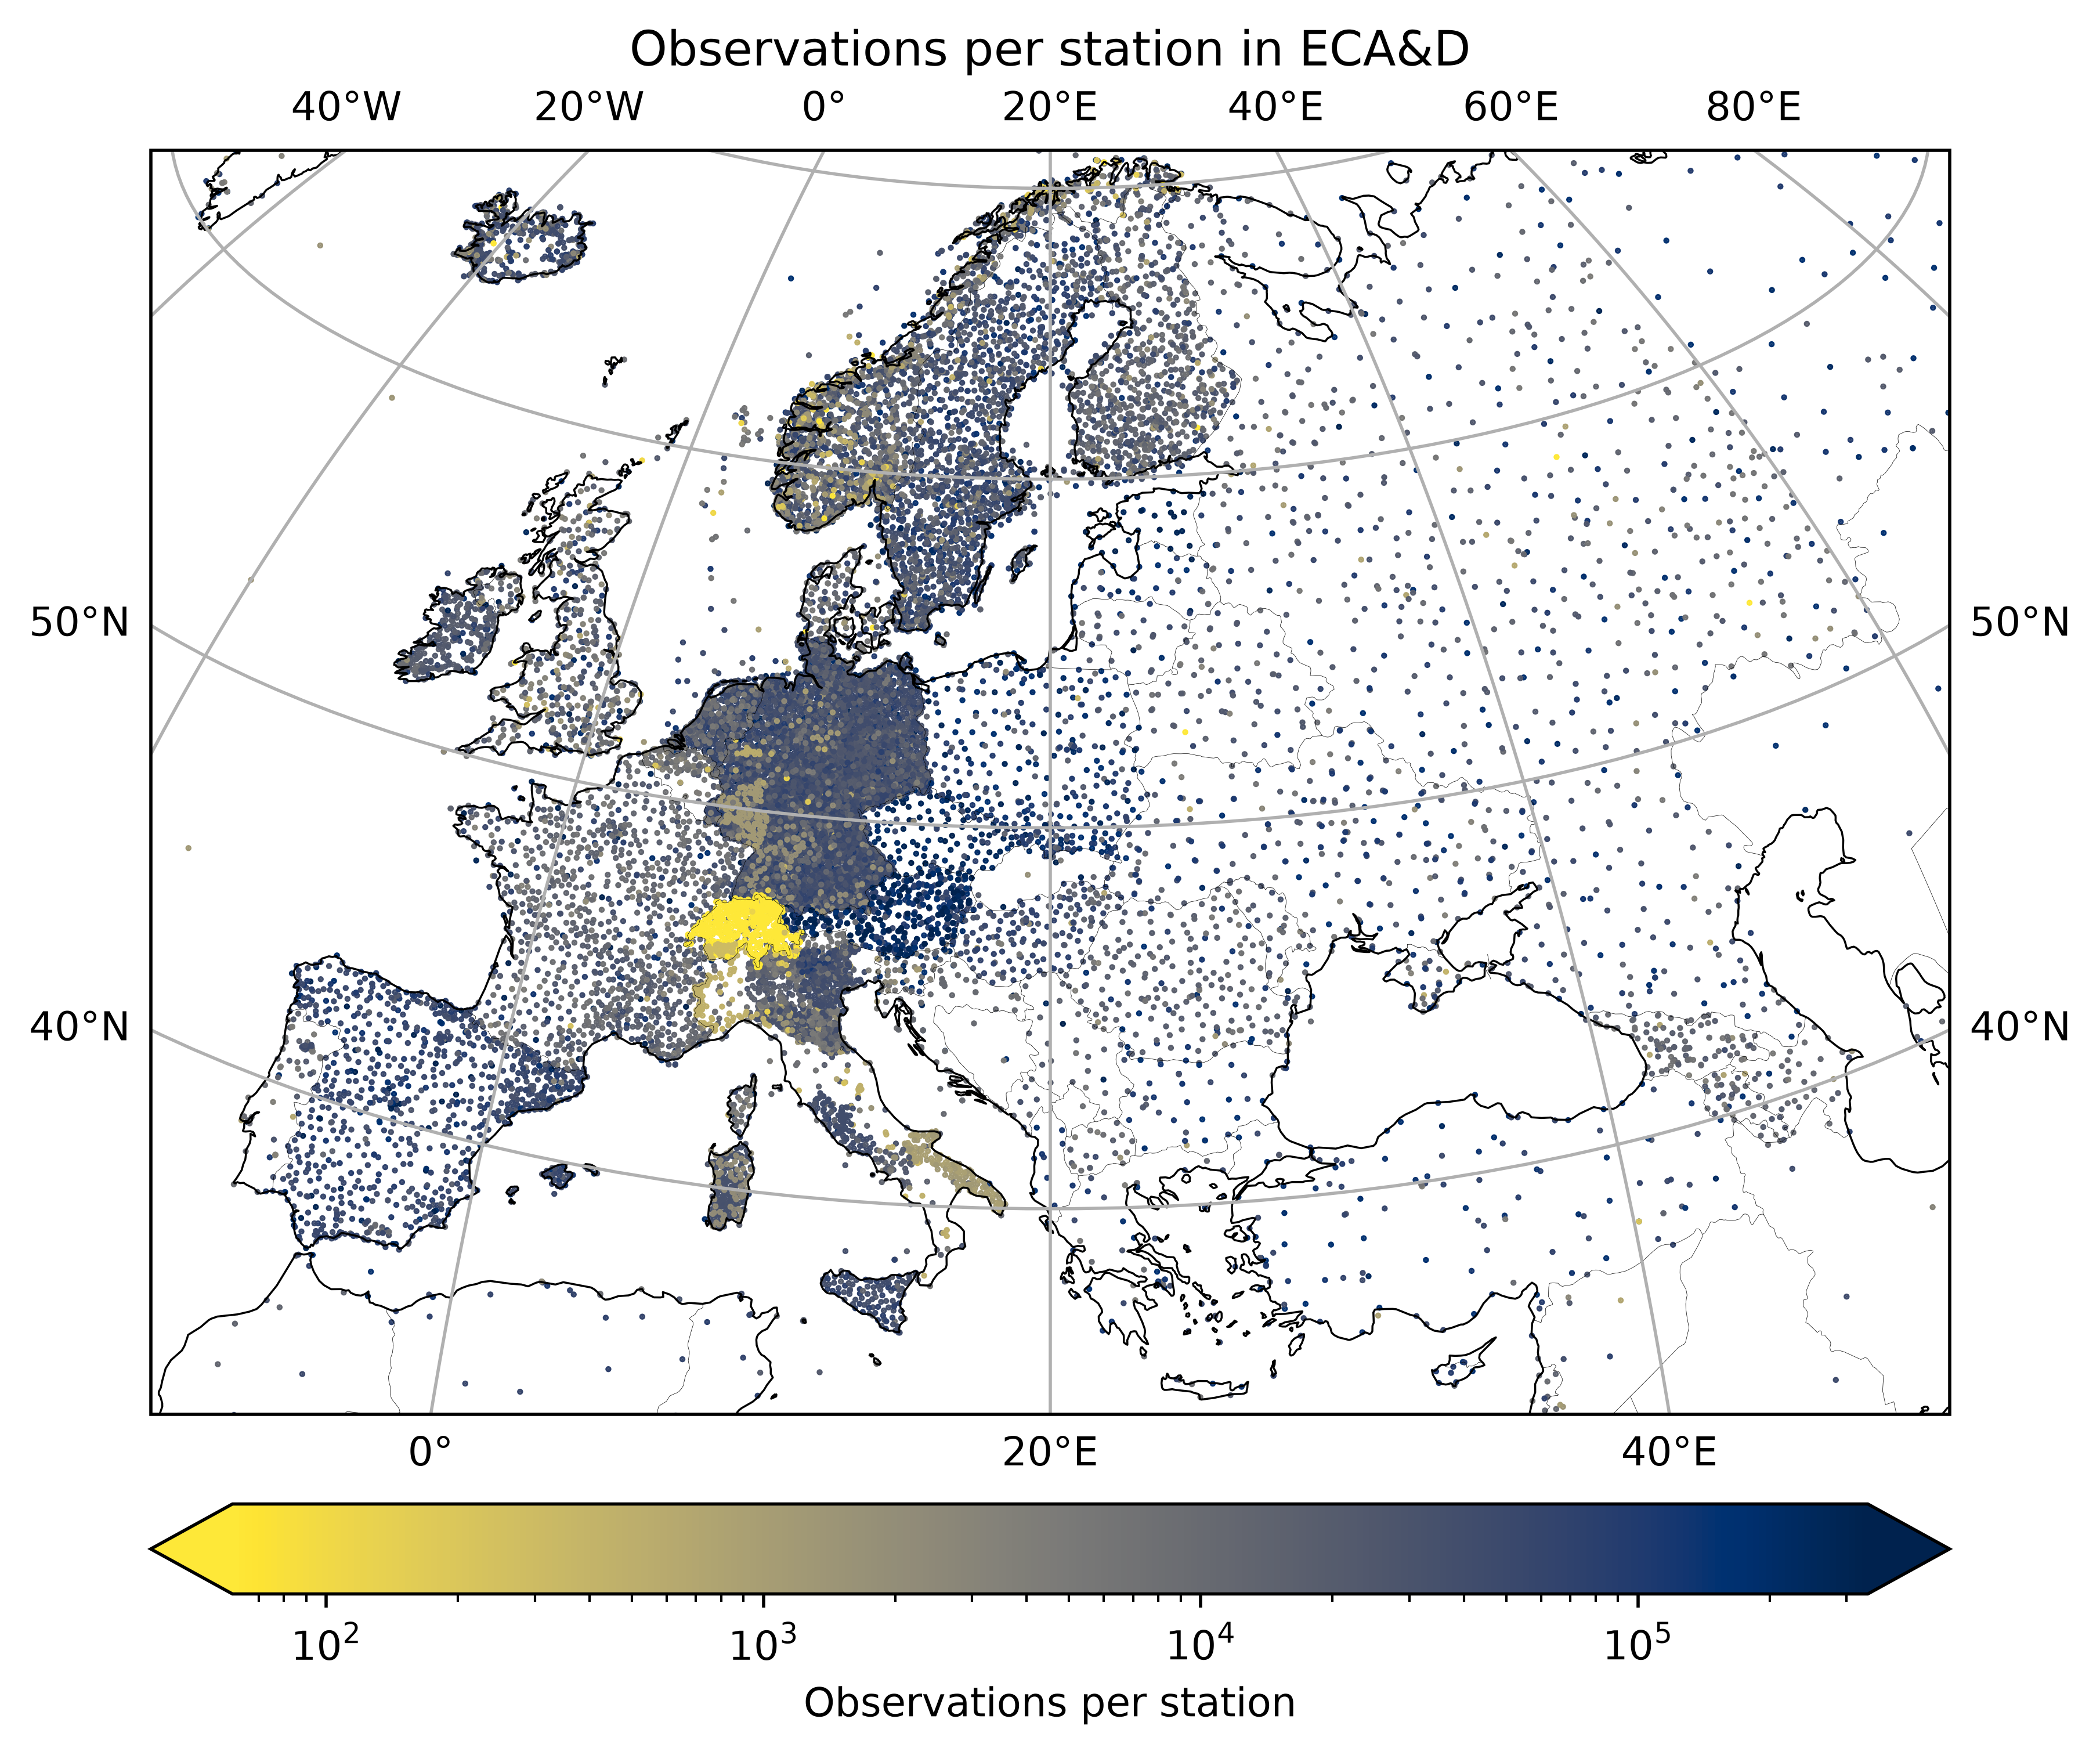

In [9]:
%%time
plt.figure(dpi=500, figsize=(8, 8))
ax = plt.subplot(
    projection=cartopy.crs.NearsidePerspective(20, 40, satellite_height=1e7)
)
ax.coastlines(lw=0.5)

ax.add_feature(cartopy.feature.BORDERS, lw=0.1)
sc = ax.scatter(
    stations_dataframe["lon"],
    stations_dataframe["lat"],
    transform=cartopy.crs.PlateCarree(),
    marker=".",
    c=stations_dataframe["n_obs"],
    norm=LogNorm(
        vmin=np.percentile(stations_dataframe.n_obs, 1),
        vmax=np.percentile(stations_dataframe.n_obs, 99),
    ),
    s=1,
    cmap="cividis_r",
)
cb = plt.colorbar(sc, orientation="horizontal", extend="both", pad=0.05)
cb.ax.set_xlabel("Observations per station")
ax.gridlines(draw_labels=True)
plt.xlim(-60, None)
ax.set_extent([-10, 50, 30, 70])
ax.set_title("Observations per station in ECA&D")

## Station De Bilt

This section demonstrates a point or small-area time-series query using De Bilt in the Netherlands as an example. The query requests mean air temperature for a small bounding box around the station and converts the returned coverage data into a DataFrame. The printed URL shows the bbox, time range, variable, and method used by the request.

In [10]:
params = {
    "method": "mean",
    "standard_name": "air_temperature",
    "bbox": "5.1,52,5.2,52.2",
    "datetime": "2025-11-01T00:00:00Z/2026-04-01T00:00:00Z",
}
data_ecad_de_bilt = get_request(f"{base_url}/collections/{collection}/cube", params)
dataframe_de_bilt_ecad = pd.DataFrame(
    dict(
        end_time=pd.to_datetime(
            data_ecad_de_bilt["coverages"][0]["domain"]["axes"]["t"]["values"]
        ),
        **{
            k: data_ecad_de_bilt["coverages"][0]["ranges"][k]["values"]
            for k in data_ecad_de_bilt["coverages"][0]["ranges"]
        },
    )
)

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/cube?method=mean&standard_name=air_temperature&bbox=5.1%2C52%2C5.2%2C52.2&datetime=2025-11-01T00%3A00%3A00Z%2F2026-04-01T00%3A00%3A00Z


API call took 0.3 s


This block plots the returned De Bilt temperature time series. The y-axis label is taken from the API response metadata, so the plot uses the parameter description and unit provided by the service.

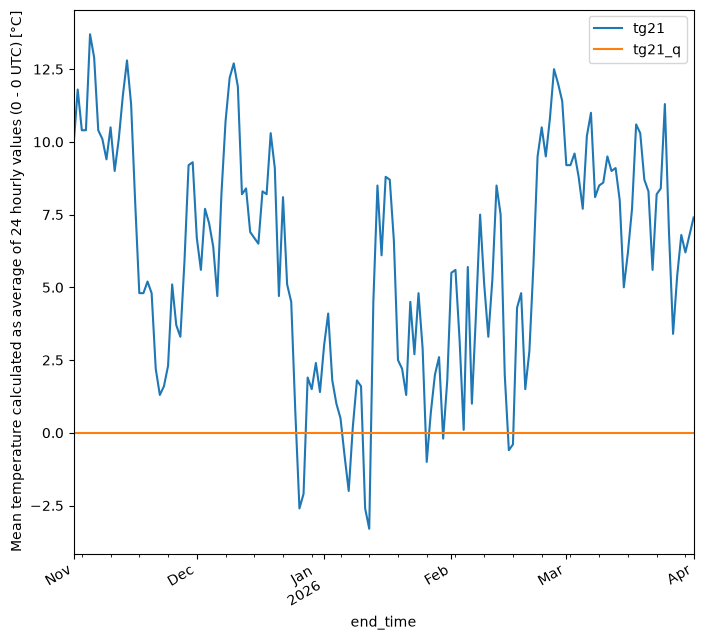

In [11]:
plt.figure(figsize=(8, 8))
dataframe_de_bilt_ecad.plot("end_time", ax=plt.gca())
desc = data_ecad_de_bilt["parameters"]["tg21"]["description"]["en"]
unit = data_ecad_de_bilt["parameters"]["tg21"]["unit"]["symbol"]["value"]
plt.ylabel(f"{desc} [{unit}]")
plt.gcf().autofmt_xdate()

# Polygon queries

The previous section queried a small bounding box around one station. Here we switch to area queries, where the API returns observations for all stations that fall inside a polygon.

## Illustrative Rhine-area polygon

This section uses a hand-drawn polygon around the Rhine corridor as an example area query. It should not be interpreted as a hydrological Rhine basin boundary: the shape is intentionally approximate and only meant to demonstrate how a WKT polygon can be passed to the API. The block below defines the polygon in Well-Known Text (WKT), converts it to a geometry object, and plots it on a simple map so we can visually check the requested area before sending it to the API.


(45.0, 57.0)

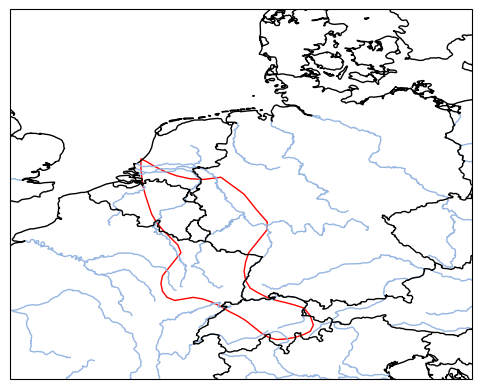

In [12]:
wkt_string = """POLYGON(( 4.25 52.15, 4.45 52.05, 4.70 51.90, 5.00 51.75, 5.40 51.60, 5.85 51.50, 6.30 51.48, 6.85 51.55, 7.6 51.0, 8 50.5, 8.35 50.10, 8.35 49.85, 8.15 49.60, 7.95 49.35, 7.75 49.10, 7.65 48.80, 7.60 48.50, 7.65 48.20, 7.80 47.95, 8.05 47.80, 8.35 47.65, 8.65 47.55, 8.95 47.48, 9.25 47.40, 9.55 47.30, 9.75 47.05, 9.85 46.75, 9.75 46.55, 9.55 46.45, 9.25 46.35, 8.95 46.30, 8.65 46.28, 8.40 46.35, 8.15 46.50, 7.90 46.70, 7.65 46.90, 7.40 47.05, 7.10 47.20, 6.85 47.35, 6.55 47.50, 6.25 47.60, 5.95 47.65, 5.65 47.60, 5.35 47.55, 5.10 47.65, 4.95 47.85, 4.90 48.10, 4.95 48.35, 5.15 48.60, 5.35 48.85, 5.55 49.10, 5.45 49.35, 5.20 49.60, 4.95 49.85, 4.75 50.10, 4.60 50.35, 4.50 50.65, 4.40 50.95, 4.32 51.25, 4.28 51.55, 4.25 51.85, 4.25 52.15 )) """


geom = wkt.loads(wkt_string)

fig = plt.figure()
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_geometries([geom], ccrs.PlateCarree(), facecolor="none", edgecolor="red")
ax.coastlines()
ax.add_feature(cartopy.feature.RIVERS)
ax.add_feature(cartopy.feature.BORDERS)
plt.xlim(0, 15)
plt.ylim(45, 57)

This block sends the illustrative Rhine-area polygon to the `/area` endpoint and requests precipitation observations for a five-day period. The API returns one coverage per matching station inside this approximate example area. The code flattens those coverages into one DataFrame, averages the available precipitation parameters into a single `rr` column, and splits the result into one DataFrame per timestamp for plotting. The printed URL shows how the polygon, time range, and variable are passed to the API.

In [13]:
params = {
    "standard_name": "precipitation_amount",
    "coords": wkt_string,
    "datetime": "2024-05-12T00:00:00Z/2024-05-16T00:00:00Z",
}
data_rhine = get_request(
    f"{base_url}/collections/{collection}/area",
    params,
)

dataframe_rhine = pd.concat(
    [
        pd.DataFrame(
            dict(
                end_time=(n_total_days := c["domain"]["axes"]["t"]["values"]),
                lon=c["domain"]["axes"]["x"]["values"]
                * len(c["domain"]["axes"]["t"]["values"]),
                lat=c["domain"]["axes"]["y"]["values"]
                * len(c["domain"]["axes"]["t"]["values"]),
                sta_id=c["eumetnet:locationId"]
                * len(c["domain"]["axes"]["t"]["values"]),
                **{k: c["ranges"][k]["values"] for k in c["ranges"]},
            )
        )
        for c in data_rhine["coverages"]
    ]
)
rr_params = [p for p in data_rhine["parameters"].keys() if not p.endswith("_q")]
dataframe_rhine["rr"] = np.nanmean(dataframe_rhine[rr_params].values, axis=1)
dataframes = [df for _, df in dataframe_rhine.groupby("end_time")]

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/area?standard_name=precipitation_amount&coords=POLYGON%28%28+4.25+52.15%2C+4.45+52.05%2C+4.70+51.90%2C+5.00+51.75%2C+5.40+51.60%2C+5.85+51.50%2C+6.30+51.48%2C+6.85+51.55%2C+7.6+51.0%2C+8+50.5%2C+8.35+50.10%2C+8.35+49.85%2C+8.15+49.60%2C+7.95+49.35%2C+7.75+49.10%2C+7.65+48.80%2C+7.60+48.50%2C+7.65+48.20%2C+7.80+47.95%2C+8.05+47.80%2C+8.35+47.65%2C+8.65+47.55%2C+8.95+47.48%2C+9.25+47.40%2C+9.55+47.30%2C+9.75+47.05%2C+9.85+46.75%2C+9.75+46.55%2C+9.55+46.45%2C+9.25+46.35%2C+8.95+46.30%2C+8.65+46.28%2C+8.40+46.35%2C+8.15+46.50%2C+7.90+46.70%2C+7.65+46.90%2C+7.40+47.05%2C+7.10+47.20%2C+6.85+47.35%2C+6.55+47.50%2C+6.25+47.60%2C+5.95+47.65%2C+5.65+47.60%2C+5.35+47.55%2C+5.10+47.65%2C+4.95+47.85%2C+4.90+48.10%2C+4.95+48.35%2C+5.15+48.60%2C+5.35+48.85%2C+5.55+49.10%2C+5.45+49.35%2C+5.20+49.60%2C+4.95+49.85%2C+4.75+50.10%2C+4.60+50.35%2C+4.50+50.65%2C+4.40+50.95%2C+4.32+51.25%2C+4.28+51.55%2C+4.25+51.85%2C+4.

API call took 0.54 s


/var/folders/3m/z6qcvmc974x8x6v54yhtqt540000gn/T/ipykernel_7901/2129130962.py:29: RuntimeWarning: Mean of empty slice
  dataframe_rhine["rr"] = np.nanmean(dataframe_rhine[rr_params].values, axis=1)


This final plotting block creates an interactive map for the illustrative Rhine-area precipitation query. The slider selects the timestamp to display, and each frame colors the returned stations by precipitation amount while keeping the approximate polygon outline visible for context.

In [14]:
kw = dict(transform=ccrs.PlateCarree(), marker=".", cmap="Blues", vmin=0, vmax=50)


def plot_frame(i):
    plt.clf()  # clear current figure
    ax = plt.axes(projection=ccrs.PlateCarree())

    df = dataframes[i]
    scat = ax.scatter(df["lon"], df["lat"], c=df["rr"], **kw)

    plt.colorbar(
        scat, orientation="vertical", label="Precipitation [mm]", pad=0.1, extend="max"
    )
    ax.coastlines()
    ax.add_feature(cartopy.feature.BORDERS)
    ax.add_geometries([geom], ccrs.PlateCarree(), facecolor="none", edgecolor="red")
    plt.title(f"{df.iloc[0]['end_time']}")


plt.figure(dpi=100)
widgets.interact(plot_frame, i=(0, len(dataframes) - 1))

<Figure size 640x480 with 0 Axes>

interactive(children=(IntSlider(value=2, description='i', max=4), Output()), _dom_classes=('widget-interact',)…

<function __main__.plot_frame(i)>

## Blended versus non-blended in the same polygon

The Rhine polygon above uses the non-blended collection. The same query on the blended collection returns more stations with a valid precipitation value on a given day. Blending fills gaps in a station series with observations from nearby stations, so more stations have data on the same day.

The next cells repeat the polygon query for the first five days of every fifth year from 1951 to 2026, for both collections. They count the stations with a valid precipitation value per day. The request helper prints the URL for the first request only, because the other requests differ only in the `datetime` parameter.

In [15]:
def polygon_precipitation(collection, start, end, print_url=False):
    """Precipitation per station and day inside the polygon, averaged over the participant variables."""
    params = {
        "standard_name": "precipitation_amount",
        "coords": wkt_string,
        "datetime": f"{start}/{end}",
    }
    url = f"{base_url}/collections/{collection}/area"
    if print_url:
        print(requests.Request("GET", url, params=params).prepare().url)
    response = requests.get(url, params=params)
    response.raise_for_status()

    rows = []
    for coverage in response.json()["coverages"]:
        rr_names = [k for k in coverage["ranges"] if k.startswith("rr") and not k.endswith("_q")]
        times = pd.to_datetime(coverage["domain"]["axes"]["t"]["values"])
        values = pd.DataFrame(
            {k: coverage["ranges"][k]["values"] for k in rr_names}, index=times
        )
        rows.append(
            pd.DataFrame(
                {
                    "station_id": coverage["eumetnet:locationId"],
                    "rr": values.mean(axis=1).to_numpy(),
                    "time": times,
                }
            )
        )
    return pd.concat(rows, ignore_index=True)


def stations_with_precipitation(collection, year):
    df = polygon_precipitation(
        collection,
        f"{year}-01-01T00:00:00Z",
        f"{year}-01-05T00:00:00Z",
        print_url=(collection == "ecad-nonblended" and year == 1951),
    ).dropna(subset=["rr"])
    return df.groupby("time")["station_id"].nunique().mean()


records = [
    dict(year=year, collection=name, stations=stations_with_precipitation(name, year))
    for year in range(1951, 2027, 5)
    for name in ["ecad-nonblended", "ecad-blended"]
]
station_counts = pd.DataFrame(records).pivot(
    index="year", columns="collection", values="stations"
)
station_counts.round(0).astype(int)

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/area?standard_name=precipitation_amount&coords=POLYGON%28%28+4.25+52.15%2C+4.45+52.05%2C+4.70+51.90%2C+5.00+51.75%2C+5.40+51.60%2C+5.85+51.50%2C+6.30+51.48%2C+6.85+51.55%2C+7.6+51.0%2C+8+50.5%2C+8.35+50.10%2C+8.35+49.85%2C+8.15+49.60%2C+7.95+49.35%2C+7.75+49.10%2C+7.65+48.80%2C+7.60+48.50%2C+7.65+48.20%2C+7.80+47.95%2C+8.05+47.80%2C+8.35+47.65%2C+8.65+47.55%2C+8.95+47.48%2C+9.25+47.40%2C+9.55+47.30%2C+9.75+47.05%2C+9.85+46.75%2C+9.75+46.55%2C+9.55+46.45%2C+9.25+46.35%2C+8.95+46.30%2C+8.65+46.28%2C+8.40+46.35%2C+8.15+46.50%2C+7.90+46.70%2C+7.65+46.90%2C+7.40+47.05%2C+7.10+47.20%2C+6.85+47.35%2C+6.55+47.50%2C+6.25+47.60%2C+5.95+47.65%2C+5.65+47.60%2C+5.35+47.55%2C+5.10+47.65%2C+4.95+47.85%2C+4.90+48.10%2C+4.95+48.35%2C+5.15+48.60%2C+5.35+48.85%2C+5.55+49.10%2C+5.45+49.35%2C+5.20+49.60%2C+4.95+49.85%2C+4.75+50.10%2C+4.60+50.35%2C+4.50+50.65%2C+4.40+50.95%2C+4.32+51.25%2C+4.28+51.55%2C+4.25+51.85%2C+4.

collection,ecad-blended,ecad-nonblended
year,,
1951,588,383
1956,621,422
1961,629,433
1966,622,430
1971,629,440
1976,631,445
1981,627,438
1986,630,439
1991,628,433


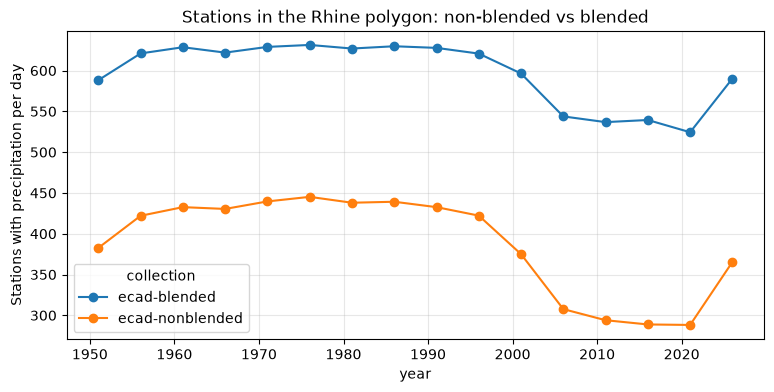

In [16]:
ax = station_counts.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("Stations with precipitation per day")
ax.set_title("Stations in the Rhine polygon: non-blended vs blended")
ax.grid(True, alpha=0.3)

The blended collection has more stations with a value in every period shown: roughly 150 to 250 more. The values also differ, because the blended series contain filled gaps and, for recent years, synoptic data. Compare the blended and non-blended series of one station in `basic_demo.ipynb`.

## Provider lineage on locations

The `provider` property of a station shows where its series comes from: which participant delivered it, for which variable, and for which period. In the blended collection, it also lists the nearby stations that fill gaps in the series.

Two points matter for the requests in this section:

- Add `verbose=true` to the `/locations` request to get the lineage. This query parameter is not listed in the Swagger documentation. The description of the `ecad-blended` collection documents it.
- The non-blended collection currently returns provider information without `verbose`. A breaking change to this format is expected soon. The helper function below reads both formats the API returns now: a dictionary per participant (non-blended) and a list of source stations (blended with `verbose=true`).

The request below uses `country_code=NL` to limit the response to the Netherlands. A request without a filter and with `verbose=true` returns more than 26,000 stations, so filter by country or by bounding box.

In [17]:
blended_nl = get_request(
    f"{base_url}/collections/ecad-blended/locations",
    {"country_code": "NL", "verbose": "true"},
)
nonblended_nl = get_request(
    f"{base_url}/collections/ecad-nonblended/locations",
    {"country_code": "NL"},
)
print(f"Blended stations: {len(blended_nl['features'])}")
print(f"Non-blended stations: {len(nonblended_nl['features'])}")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/locations?country_code=NL&verbose=true


API call took 1.4 s
https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-nonblended/locations?country_code=NL


API call took 0.36 s
Blended stations: 585
Non-blended stations: 585


The next cell prints the type of the `provider` property for De Kooy (`ecad_0000161`) in both collections. A dictionary means one entry per participant. A list means one entry per source station.

In [18]:
station_id = "ecad_0000161"  # De Kooy
for name, data in [("ecad-nonblended", nonblended_nl), ("ecad-blended", blended_nl)]:
    feature = next(f for f in data["features"] if f["id"] == station_id)
    provider = feature["properties"]["provider"]
    print(f"{name}: provider is a {type(provider).__name__} with {len(provider)} entries")

ecad-nonblended: provider is a dict with 1 entries
ecad-blended: provider is a list with 6 entries


The helper below flattens the lineage into a table with one row per source, variable, and time range. The two branches handle the two formats. If the non-blended format changes, check which branch applies by looking at the printed type above.

In [19]:
def lineage_table(feature):
    """One row per source station, variable and time range of a location."""
    providers = feature["properties"].get("provider", [])
    rows = []
    if isinstance(providers, dict):
        # Non-blended format: {participant: {variable: [[start, end], ...]}}
        for participant, variables in providers.items():
            for variable, ranges in variables.items():
                for start, end in ranges:
                    rows.append(dict(
                        source_id=feature["id"],
                        source_name=feature["properties"]["station_name"],
                        participant=participant,
                        variable=variable,
                        start=start,
                        end=end,
                    ))
    else:
        # Blended format (verbose=true): [{id, name, provider, parameters}, ...]
        for source in providers:
            for variable, info in source.get("parameters", {}).items():
                for start, end in info["ranges"]:
                    rows.append(dict(
                        source_id=source["id"],
                        source_name=source["name"],
                        participant=source["provider"],
                        variable=variable,
                        start=start,
                        end=end,
                    ))
    table = pd.DataFrame(rows)
    if table.empty:
        return table
    table["start"] = pd.to_datetime(table["start"])
    table["end"] = pd.to_datetime(table["end"])
    return table

The next cells show the lineage of De Kooy in both collections. The non-blended table only shows the series of the station itself. The blended table also shows the stations that fill the series.

In [20]:
def find_feature(data, feature_id):
    return next(f for f in data["features"] if f["id"] == feature_id)


kooy_nonblended = lineage_table(find_feature(nonblended_nl, station_id))
kooy_blended = lineage_table(find_feature(blended_nl, station_id))

print("Non-blended lineage of De Kooy:")
display(kooy_nonblended.sort_values(["variable", "start"]))

Non-blended lineage of De Kooy:


,source_id,source_name,participant,variable,start,end
0,ecad_0000161,De Kooy,Philippe Steeghs,cc1,1951-01-02,2026-10-01
1,ecad_0000161,De Kooy,Philippe Steeghs,dd1,1906-01-02,2026-10-01
2,ecad_0000161,De Kooy,Philippe Steeghs,fg1,1906-01-02,2026-10-01
3,ecad_0000161,De Kooy,Philippe Steeghs,fx1,1972-08-02,2026-10-01
4,ecad_0000161,De Kooy,Philippe Steeghs,hu3,1951-01-02,2026-10-01
5,ecad_0000161,De Kooy,Philippe Steeghs,pp2,1906-01-03,2026-10-01
6,ecad_0000161,De Kooy,Philippe Steeghs,qq2,1964-11-02,2026-10-01
7,ecad_0000161,De Kooy,Philippe Steeghs,qq6,1972-08-02,2026-10-01
8,ecad_0000161,De Kooy,Philippe Steeghs,rr7,1957-01-02,2026-10-01
9,ecad_0000161,De Kooy,Philippe Steeghs,ss3,1972-08-02,2026-10-01


In [21]:
print("Blended lineage of De Kooy:")
display(kooy_blended.sort_values(["variable", "start"]))

Blended lineage of De Kooy:


,source_id,source_name,participant,variable,start,end
0,ecad_0000161,De Kooy,Philippe Steeghs,cc,1951-01-02,2004-02-29
117,None,De Kooij,Synoptical message from GTS,cc,2004-03-01,2004-03-03
1,ecad_0000161,De Kooy,Philippe Steeghs,cc,2004-03-04,2004-08-08
118,None,De Kooij,Synoptical message from GTS,cc,2004-08-09,2004-08-09
2,ecad_0000161,De Kooy,Philippe Steeghs,cc,2004-08-10,2016-01-10
...,...,...,...,...,...,...
202,ecad_0000160,Den Helder,Philippe Steeghs,tn,1956-02-17,1956-02-17
114,ecad_0000161,De Kooy,Philippe Steeghs,tn,1956-02-18,2026-10-01
115,ecad_0000161,De Kooy,Philippe Steeghs,tx,1906-01-02,1944-09-01
203,ecad_0000160,Den Helder,Philippe Steeghs,tx,1944-09-02,1944-09-02


The blended lineage lists more source stations than the station itself. The table below counts, per participant, how many source stations and variables the blended collection uses in the Netherlands. Entries without a station id come from synoptic messages (GTS).

In [22]:
blended_sources = pd.concat(
    [lineage_table(f).assign(location_id=f["id"]) for f in blended_nl["features"]],
    ignore_index=True,
)
summary = (
    blended_sources.groupby("participant")
    .agg(
        source_stations=("source_id", "nunique"),
        locations_used=("location_id", "nunique"),
        variables=("variable", lambda v: ", ".join(sorted(set(v)))),
    )
    .sort_values("locations_used", ascending=False)
)
summary

,source_stations,locations_used,variables
participant,,,
Philippe Steeghs,499,585,"cc, dd, fg, fx, hu, pp, qq, rr, sd, ss, tg, tn..."
Synoptical message from GTS,1,69,"cc, dd, fg, fx, hu, pp, qq, rr, sd, ss, tg, tn..."
National Climate Data Center (DWD),34,29,"hu, rr, sd, ss, tg, tn, tx"
Willem Defloor,7,10,rr
Bert Heusinkveld,2,9,"dd, fg, fx, hu, pp, qq, rr, ss, tg, tn, tx"
BSRN,1,1,qq
GSOD,1,1,fg
